<a href="https://colab.research.google.com/github/ja4275/jemima_INFO4670_Fall2026/blob/main/Copy_of_Assignment3_AssociationRuleMining_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (11569 transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt


In [37]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

CSV_PATH = "bread_basket.csv"
bread = pd.read_csv(CSV_PATH)



## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [39]:
bread.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   transaction      20507 non-null  int64 
 1   item             20507 non-null  object
 2   date_time        20507 non-null  object
 3   time             20507 non-null  object
 4   period_day       20507 non-null  object
 5   weekday_weekend  20507 non-null  object
dtypes: int64(1), object(5)
memory usage: 961.4+ KB


### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [40]:
bread.describe(include = 'all')

,transaction,item,date_time,time,period_day,weekday_weekend
count,20507.000000,20507,20507,20507,20507,20507
unique,NaN,94,159,1255,4,2
top,NaN,Coffee,2017-02-04,11:06,afternoon,weekday
freq,NaN,5471,292,52,11569,12807
mean,4976.202370,NaN,NaN,NaN,NaN,NaN
std,2796.203001,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN
25%,2552.000000,NaN,NaN,NaN,NaN,NaN
50%,5137.000000,NaN,NaN,NaN,NaN,NaN
75%,7357.000000,NaN,NaN,NaN,NaN,NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

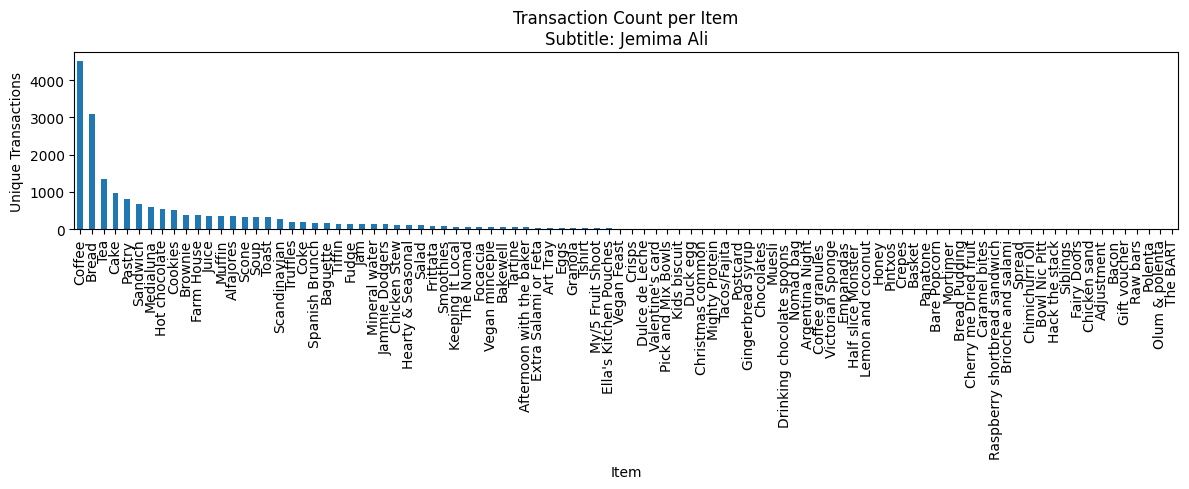

In [41]:
# c) Bar plot of transaction counts per item
subtitle = "Jemima Ali"  # <-- EDIT THIS
item_counts = bread.groupby('item')['transaction'].nunique() # <-- EDIT THIS
item_counts = item_counts.sort_values(ascending=False)

ax = item_counts.plot(kind='bar', figsize=(12,5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item"); plt.ylabel("Unique Transactions")
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [42]:
coffee_count = (bread['item'] == 'Coffee').sum()
tea_count = (bread['item'] == 'Tea').sum()
alfajores_count = (bread['item'] == 'Alfajores').sum()
juice_count = (bread['item'] == 'Juice').sum()
chicken_stew_count = (bread['item'] == 'Chicken Stew').sum()

print(f"Coffee: {coffee_count}")
print(f"Tea: {tea_count}")
print(f"Alfajores: {alfajores_count}")
print(f"Juice: {juice_count}")
print(f"Chicken Stew: {chicken_stew_count}")

Coffee: 5471
Tea: 1435
Alfajores: 369
Juice: 369
Chicken Stew: 123


## 3) Frequent Itemset Mining with FP‑Growth (min_support = 0.02) (20 pts)
We pivot the data to a **transaction × item** one‑hot table (boolean), then run FP‑Growth.

In [43]:
basket = (bread.groupby('transaction')['item'].apply(list)
                 .reset_index()
                 .sort_values('transaction')['item']
                 .tolist())

# One-hot encode
te_b = TransactionEncoder()
oht_b = pd.DataFrame(te_b.fit(basket).transform(basket), columns=te_b.columns_).astype(bool)


minsup = 0.02
minconf = 0.25

freq_b = fpgrowth(oht_b, min_support=minsup, use_colnames=True)


## 4) Association Rules + Report Table (30 pts)
(metric = confidence, min_threshold = ?) Please find a suitable min_threshold

In [44]:
rules_b = association_rules(freq_b, metric='confidence', min_threshold=minconf)
rules_b[['antecedents','consequents','support','confidence','lift']].sort_values(['lift','confidence'], ascending=False)

,antecedents,consequents,support,confidence,lift
10,(Toast),(Coffee),0.023666,0.704403,1.472431
5,(Medialuna),(Coffee),0.035182,0.569231,1.189878
3,(Pastry),(Coffee),0.047544,0.552147,1.154168
7,(Juice),(Coffee),0.020602,0.534247,1.116750
9,(Sandwich),(Coffee),0.038246,0.532353,1.112792
8,(Cake),(Coffee),0.054728,0.526958,1.101515
2,(Cookies),(Coffee),0.028209,0.518447,1.083723
1,(Hot chocolate),(Coffee),0.029583,0.507246,1.060311
4,(Pastry),(Bread),0.029160,0.338650,1.034977
6,(Tea),(Coffee),0.049868,0.349630,0.730840


## 5) Interpretation (10 pts)
**Interpret the rule `{Coffee, Cake} ⇒ {Bread}` in plain English.**

- **Support**: What fraction of *all* transactions contain Coffee, Cake, and Bread together?
- **Confidence**: Among baskets with Coffee and Cake, what share also include Bread?
- **Lift > 1** implies positive association; comment on practical meaning.

*Your notes:* Support is about 0.010 so 1% of all transactions contain Coffee, Cake, and Bread together. Confidence is about 0.183 or 18.3% of baskets with Coffee and Cake also includes Bread. Lift is about 0.560. The lift is below 1 meaning negative association indicating transactions containing coffee and cake are less likely to contain bread compared to a random transaction. If lift was more than one, transactions containing coffee and cake would be more likely to contain bread compared to a random transaction.

Coffee, Cake ⇒ Bread Support: 0.010036978341257264
Coffee, Cake ⇒ Bread Confidence: 0.1833976833976834
Coffee, Cake ⇒ Bread Lift: 0.5604969562024777


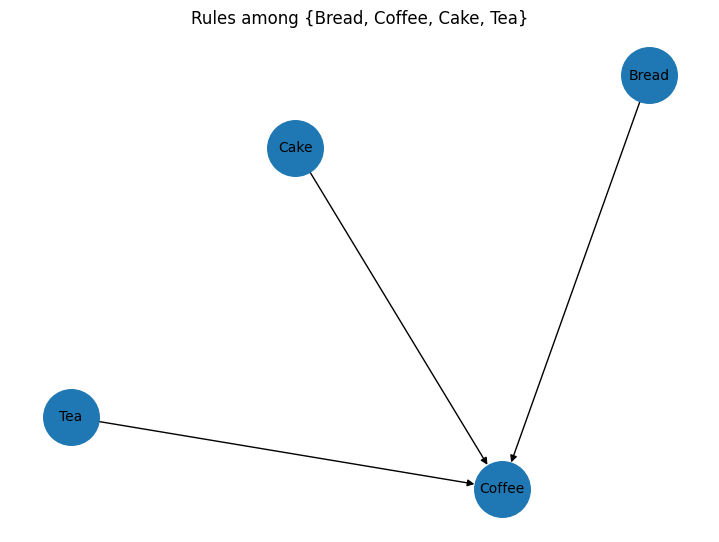

In [45]:
support_ccb = (oht_b['Coffee'] & oht_b['Cake'] & oht_b['Bread']).mean()
print(f"Coffee, Cake ⇒ Bread Support: {support_ccb}")

confidence_ccb = (oht_b['Coffee'] & oht_b['Cake'] & oht_b['Bread']).sum() / (oht_b['Coffee'] & oht_b['Cake']).sum()
print(f"Coffee, Cake ⇒ Bread Confidence: {confidence_ccb}")

lift_ccb = confidence_ccb / (oht_b['Bread']).mean()
print (f"Coffee, Cake ⇒ Bread Lift: {lift_ccb}")

import networkx as nx

focus = {'Bread','Coffee','Cake','Tea'}
sub = rules_b[
    rules_b['antecedents'].apply(lambda s: s.issubset(focus)) &
    rules_b['consequents'].apply(lambda s: s.issubset(focus))
].copy()

G = nx.DiGraph()
for _, r in sub.iterrows():
    a = ','.join(sorted(list(r['antecedents'])))
    c = ','.join(sorted(list(r['consequents'])))
    G.add_edge(a, c, weight=float(r['confidence']), lift=float(r['lift']))

plt.figure(figsize=(7,5))
pos = nx.spring_layout(G, seed=0)
nx.draw(G, pos, with_labels=True, node_size=1600, font_size=10, arrows=True)
plt.title("Rules among {Bread, Coffee, Cake, Tea}")
plt.show()